# StatsBomb EDA: 2022 World Cup formations and 360 data

Formation EDA only (competition 43, season 106), no models. Everything pulled through `statsbombpy` is cached in `data/raw/statsbomb` (git-ignored) by `src/statsbomb_loaders.py`, so re-running doesn't hit the API again.

Two units to keep apart:
- team-match: one team in one match. This is the independent unit.
- snapshot: one team's view of one 360 freeze-frame. There are thousands per team-match and they're highly correlated, so snapshot counts are inflated.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from src import statsbomb_loaders as sl

FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

BAR, RARE_C = "#2a6fb0", "#c4601a"
INK, MUTED, GRID = "#1f2328", "#59636e", "#d8dee4"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})
def save(fig, name):
    p = FIG_DIR / name; fig.savefig(p, bbox_inches="tight", facecolor="white"); print("saved", p.relative_to(ROOT))
def style(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, lw=0.6); ax.set_axisbelow(True)

# first run pulls from the API, later runs read the cache
print(sl.cache_all(verbose=False))
matches = sl.get_matches()
tac = sl.tactics_table()
lab = sl.formation_labels(tac)
frames = sl.build_frame_table()
snaps = sl.team_view_table(frames, tac)
print(f"matches={len(matches)}  tactics events={len(tac)}  freeze-frames={len(frames):,}  team-view snapshots={len(snaps):,}")

{'fetched': 0, 'cached': 128}


matches=64  tactics events=371  freeze-frames=203,882  team-view snapshots=407,764


## 1. Coverage

In [2]:
n_matches = len(matches)
fpm = frames.groupby("match_id").size().reindex(matches.match_id.astype(int), fill_value=0)
n_with_frames = int((fpm > 0).sum())
print(f"World Cup matches total:                    {n_matches}")
print(f"match_status_360 flag:                      {matches.match_status_360.value_counts().to_dict()}")
print(f"matches with >=1 freeze-frame actually loaded: {n_with_frames}")
print(f"freeze-frames per match: min {fpm.min()} / median {int(fpm.median())} / max {fpm.max()}  (total {fpm.sum():,})")
print("\nmatches by stage:"); print(matches.competition_stage.value_counts().to_string())

World Cup matches total:                    64
match_status_360 flag:                      {'available': 64}
matches with >=1 freeze-frame actually loaded: 64
freeze-frames per match: min 2373 / median 3101 / max 4511  (total 203,882)

matches by stage:
competition_stage
Group Stage        48
Round of 16         8
Quarter-finals      4
Semi-finals         2
Final               1
3rd Place Final     1


In [3]:
# team-match counts: teams x matches -> labelled -> with 360
tm = lab.copy()
nsnap = snaps.groupby(["match_id", "team"]).size().rename("n_snapshots").reset_index()
tm = tm.merge(nsnap, on=["match_id", "team"], how="left").fillna({"n_snapshots": 0})
tm["has_label"] = tm.formation_start.notna() & tm.tactics_ok
tm["has_360"] = tm.n_snapshots > 0
tm["independent"] = tm.has_label & tm.has_360

acct = pd.Series({
    "matches": n_matches,
    "teams (distinct)": tm.team.nunique(),
    "team-matches = teams x matches (2 per match)": 2 * n_matches,
    "team-matches with a Starting XI row": len(tm),
    "  ... with a usable formation label": int(tm.has_label.sum()),
    "  ... with >=1 360 snapshot": int(tm.has_360.sum()),
    "INDEPENDENT labelled team-matches (label AND 360)": int(tm.independent.sum()),
    "total snapshots (inflated)": int(len(snaps[snaps.formation_start.notna()])),
}, name="count")
acct.to_frame()

,count
matches,64
teams (distinct),32
team-matches = teams x matches (2 per match),128
team-matches with a Starting XI row,128
... with a usable formation label,128
... with >=1 360 snapshot,128
INDEPENDENT labelled team-matches (label AND 360),128
total snapshots (inflated),407764


saved reports\figures\09_sb_coverage.png


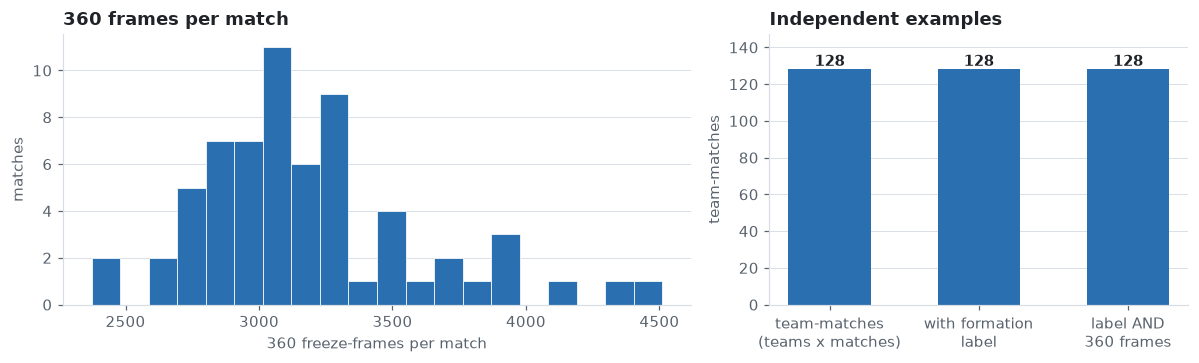

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [3, 2]})
axes[0].hist(fpm, bins=20, color=BAR, edgecolor="white", lw=0.5)
axes[0].set_xlabel("360 freeze-frames per match"); axes[0].set_ylabel("matches"); axes[0].set_title("360 frames per match"); style(axes[0], "y")
vals = [acct.iloc[0] * 2, int(tm.has_label.sum()), int(tm.independent.sum())]
names = ["team-matches\n(teams x matches)", "with formation\nlabel", "label AND\n360 frames"]
axes[1].bar(names, vals, color=BAR, width=0.55)
for x, v in enumerate(vals): axes[1].text(x, v + 2, str(v), ha="center", fontweight="bold")
axes[1].set_ylim(0, max(vals) * 1.15); axes[1].set_title("Independent examples"); axes[1].set_ylabel("team-matches"); style(axes[1], "y")
fig.tight_layout(); save(fig, "09_sb_coverage.png"); plt.show()

## 2. Starting formations vs mid-match shifts

In [5]:
shifts = tac[tac["type"] == "Tactical Shift"].copy()
start_counts = lab.loc[lab.tactics_ok, "formation_start"].value_counts()
shift_counts = shifts["formation"].value_counts()

dist = pd.DataFrame({"starting (team-matches)": start_counts, "tactical-shift events": shift_counts}).fillna(0).astype(int)
dist = dist.sort_values(["starting (team-matches)", "tactical-shift events"], ascending=False)
dist["start_share_%"] = (dist["starting (team-matches)"] / dist["starting (team-matches)"].sum() * 100).round(1)
dist["shift_share_%"] = (dist["tactical-shift events"] / dist["tactical-shift events"].sum() * 100).round(1)
print(f"STARTING formations: {int(start_counts.sum())} team-matches, {start_counts.size} distinct formations")
print(f"TACTICAL SHIFTS:     {len(shifts)} events, {shift_counts.size} distinct formations, "
      f"in {shifts.groupby(['match_id','team']).ngroups} of {len(tm)} team-matches")
dist

STARTING formations: 128 team-matches, 10 distinct formations
TACTICAL SHIFTS:     243 events, 10 distinct formations, in 117 of 128 team-matches


,starting (team-matches),tactical-shift events,start_share_%,shift_share_%
433,36,51,28.1,21.0
4231,32,56,25.0,23.0
442,17,36,13.3,14.8
352,11,23,8.6,9.5
343,8,33,6.2,13.6
3421,7,13,5.5,5.3
3412,6,8,4.7,3.3
4141,6,7,4.7,2.9
4411,4,15,3.1,6.2
41212,1,0,0.8,0.0


In [6]:
# does a shift change the formation? compare to the team's previous one
tt = tac[tac.tactics_ok].sort_values(["match_id", "team", "index"]).copy()
tt["prev"] = tt.groupby(["match_id", "team"])["formation"].shift(1)
sh = tt[tt["type"] == "Tactical Shift"]
print(f"shift events: {len(sh)} | change the formation: {(sh.formation != sh.prev).sum()} | same formation (e.g. role swap): {(sh.formation == sh.prev).sum()}")
per_tm = shifts.groupby(["match_id", "team"]).size().reindex(pd.MultiIndex.from_frame(lab[["match_id", "team"]]), fill_value=0)
print("shift events per team-match:", per_tm.value_counts().sort_index().to_dict())
print(f"team-matches whose formation CHANGES at least once: {sh[sh.formation != sh.prev].groupby(['match_id','team']).ngroups}")
print("\nlineup size listed at each shift:", shifts.lineup_len.value_counts().sort_index().to_dict(), "(always 11: lineup size does not drop after a red card, e.g. Wales at 83 min)")

shift events: 243 | change the formation: 90 | same formation (e.g. role swap): 153
shift events per team-match: {0: 11, 1: 40, 2: 42, 3: 25, 4: 8, 5: 1, 7: 1}
team-matches whose formation CHANGES at least once: 68

lineup size listed at each shift: {11: 243} (always 11: lineup size does not drop after a red card, e.g. Wales at 83 min)


saved reports\figures\10_sb_formation_distribution.png


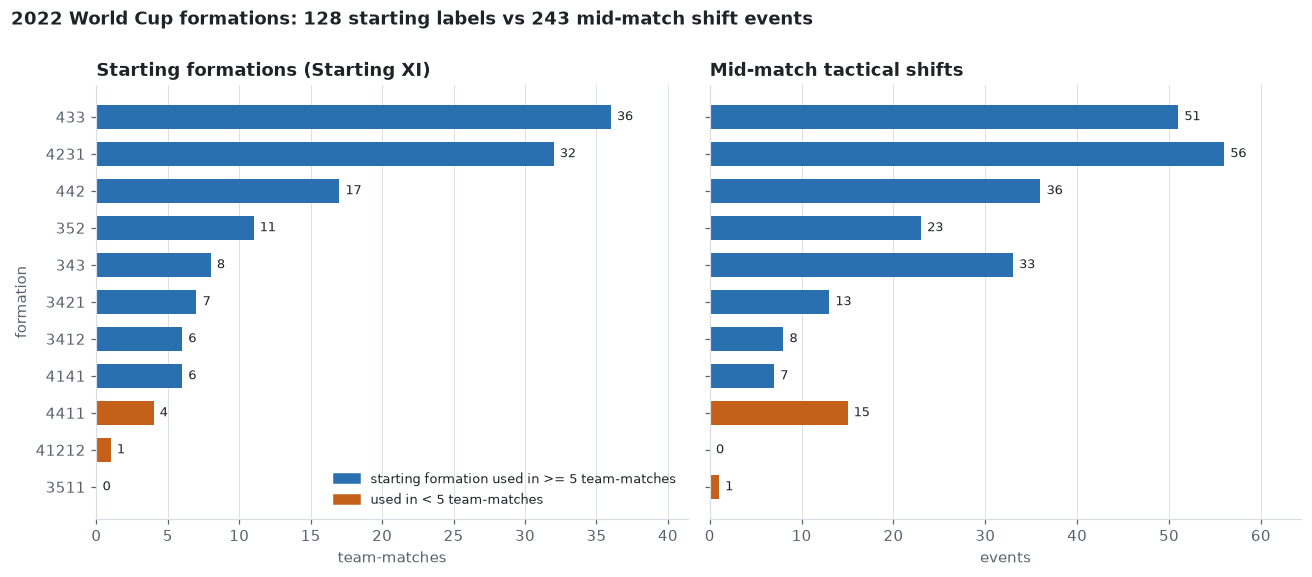

In [7]:
d = dist.iloc[::-1]
RARE_N = 5   # starting formation used by fewer than 5 team-matches
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, col, title in zip(axes, ["starting (team-matches)", "tactical-shift events"],
                          ["Starting formations (Starting XI)", "Mid-match tactical shifts"]):
    ax.barh(d.index, d[col], height=0.65,
            color=[RARE_C if d.loc[f, "starting (team-matches)"] < RARE_N else BAR for f in d.index])
    for y, v in enumerate(d[col]):
        ax.text(v + d[col].max() * 0.012, y, str(v), va="center", fontsize=8.5)
    ax.set_title(title); ax.set_xlim(0, d[col].max() * 1.15); style(ax)
axes[0].set_xlabel("team-matches"); axes[1].set_xlabel("events")
axes[0].set_ylabel("formation")
axes[0].legend(handles=[Patch(color=BAR, label=f"starting formation used in >= {RARE_N} team-matches"),
                        Patch(color=RARE_C, label=f"used in < {RARE_N} team-matches")],
               loc="lower right", frameon=False, fontsize=8.5)
fig.suptitle(f"2022 World Cup formations: {int(start_counts.sum())} starting labels vs {len(shifts)} mid-match shift events",
             x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "10_sb_formation_distribution.png"); plt.show()

## 3. Players visible per freeze-frame

In [8]:
s = frames.n_total
print(f"{len(frames):,} freeze-frames | players visible per frame: mean {s.mean():.1f} / median {s.median():.0f} / min {s.min()} / max {s.max()}")
print(f"frames showing all 22 players: {(s >= 22).mean():.2%} | <= 10 players: {(s <= 10).mean():.1%} | >= 16: {(s >= 16).mean():.1%}")
v = snaps.n_visible
print(f"\nper-team snapshot ({len(snaps):,}): own players visible mean {v.mean():.1f} / median {v.median():.0f}; "
      f"full XI (>=11) visible in {(v >= 11).mean():.2%}; >=10 in {(v >= 10).mean():.1%}; <=5 in {(v <= 5).mean():.1%}")
print("\nevent team vs opponent visible (mean):", round(frames.n_event_team.mean(), 1), "vs", round(frames.n_opponent.mean(), 1))
print("\nvisible players per frame, quantiles:"); print(s.quantile([.01, .05, .25, .5, .75, .95, .99]).to_string())

203,882 freeze-frames | players visible per frame: mean 15.1 / median 16 / min 1 / max 22
frames showing all 22 players: 0.00% | <= 10 players: 11.3% | >= 16: 51.6%

per-team snapshot (407,764): own players visible mean 7.6 / median 8; full XI (>=11) visible in 3.02%; >=10 in 20.3%; <=5 in 16.5%

event team vs opponent visible (mean): 7.6 vs 7.6

visible players per frame, quantiles:
0.01     5.0
0.05     9.0
0.25    13.0
0.50    16.0
0.75    18.0
0.95    20.0
0.99    20.0


saved reports\figures\11_sb_players_visible.png


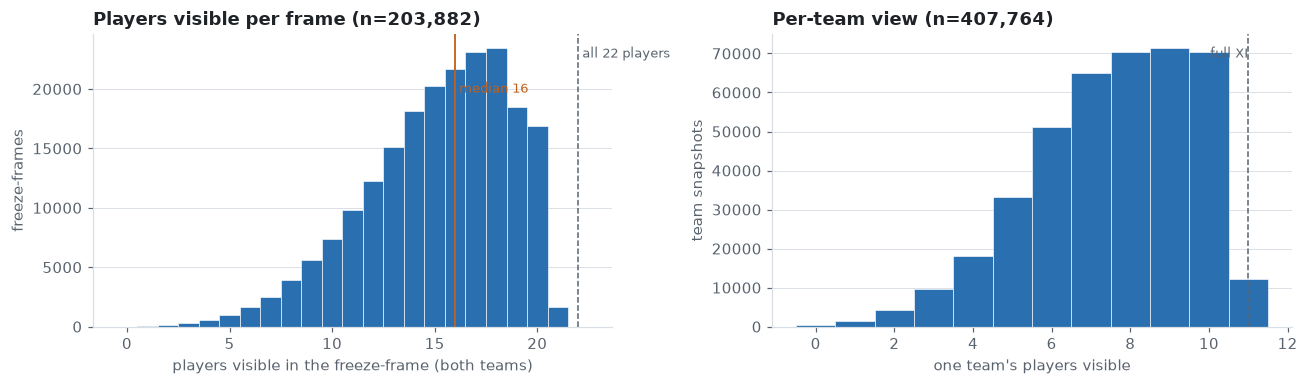

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
b = np.arange(-0.5, max(frames.n_total.max(), 22) + 1.5, 1)
axes[0].hist(frames.n_total, bins=b, color=BAR, edgecolor="white", lw=0.4)
axes[0].axvline(22, color=MUTED, ls="--", lw=1); axes[0].text(22, axes[0].get_ylim()[1] * 0.92, " all 22 players", color=MUTED, fontsize=8.5)
axes[0].axvline(s.median(), color=RARE_C, lw=1.2); axes[0].text(s.median(), axes[0].get_ylim()[1] * 0.80, f" median {s.median():.0f}", color=RARE_C, fontsize=8.5)
axes[0].set_xlabel("players visible in the freeze-frame (both teams)"); axes[0].set_ylabel("freeze-frames")
axes[0].set_title(f"Players visible per frame (n={len(frames):,})"); style(axes[0], "y")
b2 = np.arange(-0.5, 12.5, 1)
axes[1].hist(snaps.n_visible, bins=b2, color=BAR, edgecolor="white", lw=0.4)
axes[1].axvline(11, color=MUTED, ls="--", lw=1); axes[1].text(11, axes[1].get_ylim()[1] * 0.92, " full XI", color=MUTED, fontsize=8.5, ha="right")
axes[1].set_xlabel("one team's players visible"); axes[1].set_ylabel("team snapshots")
axes[1].set_title(f"Per-team view (n={len(snaps):,})"); style(axes[1], "y")
fig.tight_layout(); save(fig, "11_sb_players_visible.png"); plt.show()

## 4. Joining formation labels to snapshots

Each freeze-frame gives two snapshots, one for the event team's visible players and one for the opponent's. Each snapshot gets its team's starting formation. `formation_active` (the latest tactics event at or before the frame) is attached too, to show how much the labels drift after mid-match shifts.

In [10]:
valid = snaps[snaps.formation_start.notna()]
by_tm = valid.drop_duplicates(["match_id", "team"])["formation_start"].value_counts()
by_snap = valid["formation_start"].value_counts()
cmp = pd.DataFrame({"team_matches (independent)": by_tm, "snapshots (inflated)": by_snap}).fillna(0).astype(int)
cmp["snaps_per_team_match"] = (cmp["snapshots (inflated)"] / cmp["team_matches (independent)"]).round(0).astype(int)
cmp["team_match_share_%"] = (cmp["team_matches (independent)"] / cmp["team_matches (independent)"].sum() * 100).round(1)
cmp["snapshot_share_%"] = (cmp["snapshots (inflated)"] / cmp["snapshots (inflated)"].sum() * 100).round(1)
cmp = cmp.sort_values("team_matches (independent)", ascending=False)
print(f"TOTAL: {int(cmp['team_matches (independent)'].sum())} team-matches (independent)  vs  {int(cmp['snapshots (inflated)'].sum()):,} snapshots (inflated)  "
      f"=> ~{cmp['snapshots (inflated)'].sum() / cmp['team_matches (independent)'].sum():.0f} snapshots per team-match")
print(f"snapshots whose ACTIVE formation differs from the starting label: {valid.formation_shifted.mean():.1%} ({int(valid.formation_shifted.sum()):,})")
cmp

TOTAL: 128 team-matches (independent)  vs  407,764 snapshots (inflated)  => ~3186 snapshots per team-match
snapshots whose ACTIVE formation differs from the starting label: 15.8% (64,242)


,team_matches (independent),snapshots (inflated),snaps_per_team_match,team_match_share_%,snapshot_share_%
formation_start,,,,,
433,36,118570,3294,28.1,29.1
4231,32,98477,3077,25.0,24.2
442,17,53085,3123,13.3,13.0
352,11,35000,3182,8.6,8.6
343,8,27574,3447,6.2,6.8
3421,7,21227,3032,5.5,5.2
3412,6,19342,3224,4.7,4.7
4141,6,18395,3066,4.7,4.5
4411,4,13152,3288,3.1,3.2


saved reports\figures\12_sb_class_counts_two_ways.png


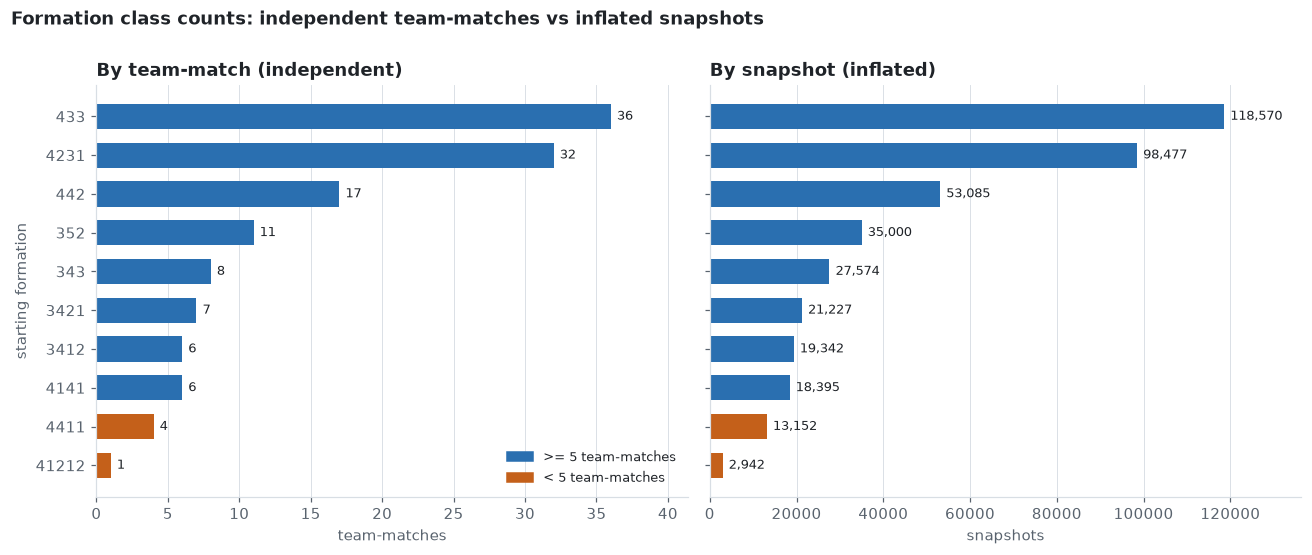

In [11]:
c = cmp.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, col, title in zip(axes, ["team_matches (independent)", "snapshots (inflated)"],
                          ["By team-match (independent)", "By snapshot (inflated)"]):
    ax.barh(c.index, c[col], height=0.65, color=[RARE_C if n < RARE_N else BAR for n in c["team_matches (independent)"]])
    for y, v_ in enumerate(c[col]): ax.text(v_ + c[col].max() * 0.012, y, f"{v_:,}", va="center", fontsize=8.5)
    ax.set_title(title); ax.set_xlim(0, c[col].max() * 1.15); style(ax)
axes[0].set_xlabel("team-matches"); axes[1].set_xlabel("snapshots"); axes[0].set_ylabel("starting formation")
axes[0].legend(handles=[Patch(color=BAR, label=f">= {RARE_N} team-matches"), Patch(color=RARE_C, label=f"< {RARE_N} team-matches")],
               loc="lower right", frameon=False, fontsize=8.5)
fig.suptitle("Formation class counts: independent team-matches vs inflated snapshots", x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "12_sb_class_counts_two_ways.png"); plt.show()

In [12]:
# test set size per class if we split by match
eff = cmp[["team_matches (independent)", "snapshots (inflated)"]].copy()
eff["max_test_team_matches_at_20%"] = np.floor(eff["team_matches (independent)"] * 0.2).astype(int)
print("classes with < 5 team-matches:", eff.index[eff["team_matches (independent)"] < 5].tolist())
print("classes with exactly 1 team-match:", eff.index[eff["team_matches (independent)"] == 1].tolist())
print("classes that would get 0 test team-matches under a 20% split:", eff.index[eff["max_test_team_matches_at_20%"] == 0].tolist())
eff

classes with < 5 team-matches: ['4411', '41212']
classes with exactly 1 team-match: ['41212']
classes that would get 0 test team-matches under a 20% split: ['4411', '41212']


,team_matches (independent),snapshots (inflated),max_test_team_matches_at_20%
formation_start,,,
433,36,118570,7
4231,32,98477,6
442,17,53085,3
352,11,35000,2
343,8,27574,1
3421,7,21227,1
3412,6,19342,1
4141,6,18395,1
4411,4,13152,0


## 5. Data quality

In [13]:
q = {}
# 360 coverage
q["matches flagged not 'available' for 360"] = int((matches.match_status_360 != "available").sum())
q["matches with 0 freeze-frames loaded"] = int((fpm == 0).sum())
q["matches with < 500 freeze-frames"] = int((fpm < 500).sum())
# frames
q["frames whose event_uuid is not in the events file"] = int((~frames.event_found).sum())
q["frames with no visible_area"] = int((~frames.has_visible_area).sum())
q["duplicate freeze-frames (same event_id)"] = int(frames.duplicated(["match_id", "event_id"]).sum())
for k in (0, 3, 5, 7):
    q[f"frames with <= {k} visible players (both teams)"] = int((frames.n_total <= k).sum())
q["team snapshots with <= 3 own players visible"] = int((snaps.n_visible <= 3).sum())
q["team snapshots with 0 own players visible"] = int((snaps.n_visible == 0).sum())
# tactics
q["tactics events (Starting XI + Tactical Shift)"] = len(tac)
q["tactics entries malformed (not dict / no formation / no lineup list)"] = int((~tac.tactics_ok).sum())
q["tactics with missing formation"] = int(tac.formation.isna().sum())
q["formation not an int in the raw JSON"] = int((~tac.formation_raw.map(lambda x: isinstance(x, int) and not isinstance(x, bool))).sum())
ds = tac.formation.dropna().map(lambda s: sum(int(c) for c in s))
q["formation digits not summing to 10 outfield players"] = int((ds != 10).sum())
sx = tac[tac["type"] == "Starting XI"]
q["Starting XI with lineup != 11 players"] = int((sx.lineup_len != 11).sum())
q["matches without exactly 2 Starting XI events"] = int((sx.groupby("match_id").size().reindex(matches.match_id.astype(int), fill_value=0) != 2).sum())
q["Tactical Shift with lineup != 11 players"] = int((shifts.lineup_len != 11).sum())
q["team-matches with no label or no snapshots"] = int((~tm.independent).sum())
# team names match between matches table and events?
mt = set(matches.home_team) | set(matches.away_team)
q["team names in events but not in matches table"] = int(len(set(tac.team.dropna()) - mt))
pd.Series(q, name="result").to_frame()

,result
matches flagged not 'available' for 360,0
matches with 0 freeze-frames loaded,0
matches with < 500 freeze-frames,0
frames whose event_uuid is not in the events file,0
frames with no visible_area,0
duplicate freeze-frames (same event_id),0
frames with <= 0 visible players (both teams),0
frames with <= 3 visible players (both teams),508
frames with <= 5 visible players (both teams),2082
frames with <= 7 visible players (both teams),6165


In [14]:
# look at the odd rows, not just the counts
print("formation codes (all tactics events):", sorted(tac.formation.dropna().unique(), key=lambda s: (len(s), s)))
odd = tac[(~tac.tactics_ok) | tac.formation.isna() | (tac.formation.dropna().map(lambda s: sum(int(c) for c in s)) != 10).reindex(tac.index, fill_value=False)]
print("\nmalformed / odd-sum tactics rows:", "none" if odd.empty else "")
if not odd.empty: print(odd[["match_id", "team", "type", "minute", "formation_raw", "lineup_len"]].to_string())
low = frames[frames.n_total <= 3]
print(f"\nfew-player frames (<=3 visible): {len(low)}; by event type:", low.event_type.value_counts().head(5).to_dict() if len(low) else "none")
print("event types of ALL freeze-frames (top 8):", frames.event_type.value_counts().head(8).to_dict())

formation codes (all tactics events): ['343', '352', '433', '442', '3412', '3421', '3511', '4141', '4231', '4411', '41212']

malformed / odd-sum tactics rows: none

few-player frames (<=3 visible): 508; by event type: {'Pass': 170, 'Carry': 134, 'Ball Receipt*': 126, 'Shot': 34, 'Ball Recovery': 33}
event types of ALL freeze-frames (top 8): {'Pass': 57393, 'Ball Receipt*': 57217, 'Carry': 49406, 'Pressure': 14504, 'Ball Recovery': 5197, 'Duel': 3777, 'Clearance': 2476, 'Block': 2094}


## 6. Takeaways

- There are only 128 independent examples, however many frames there are. All 64 matches have 360 data (203,882 freeze-frames, 2,373 to 4,511 per match) and all 128 team-matches have a starting formation. The 407,764 team snapshots are about 3,186 per team-match and tightly correlated, so 128 is the real sample size.
- Starting formations bunch up at the top. 433 (36 team-matches) and 4231 (32) are 53% of the labels, followed by 442 (17), 352 (11), 343 (8), 3421 (7), 3412 (6) and 4141 (6). 4411 (4) and 41212 (1) are rare. During matches there are 243 Tactical Shift events across 117 of the 128 team-matches, but only 90 change the formation (153 repeat it, for example a role swap), and 68 team-matches change formation at least once. Using the starting formation for every snapshot is out of date for 15.8% of them. 3511 only shows up as a shift.
- The camera only sees about half of each team. A frame shows a median of 16 of the 22 players, but only about 7.6 of one team's players (median 8). The full XI is visible in 3.0% of team snapshots and 10 or more in 20.3%. 16.5% show 5 or fewer, and 394 show none, so snapshots will probably need filtering or weighting by how many players are visible.
- With a split by match, the test sets per class are tiny. At a 20% split, 433 gets 7 test team-matches, 4231 gets 6, 442 gets 3, 352 gets 2, 343/3421/3412/4141 get 1 each, and 4411 and 41212 get none. Per-class accuracy will be noisy, so leave-match-out CV, intervals over team-matches, and merging or dropping the rare formations are worth considering. Otherwise the data is clean (no missing 360, no malformed tactics). One oddity: the listed lineup stays at 11 after a red card (Wales, 83'), so labels after a red card may not match a 10-man shape.